In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Colab Notebooks/Oraldiseaseimage/oral_diseasecleanzip.zip"
extract_to = "/content/oral_disease_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print("Extraction complete!")

Extraction complete!


In [ ]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from PIL import Image


data_dir = "/content/oral_disease_data/oral_diseaseclean"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

print(f"Total images found: {len(dataset)}")
print(f"Classes: {dataset.classes}")

Total images found: 9036
Classes: ['Calculus', 'Gingivitis', 'Hypodontia', 'MouthUlcer', 'ToothCaries', 'ToothDicoloration']


In [ ]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split


transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


data_path = '/content/oral_disease_data/oral_diseaseclean'
full_dataset = ImageFolder(root=data_path, transform=transform)

train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
images, labels = next(iter(train_loader))
print("Train batch shape:", images.shape)

Train batch shape: torch.Size([32, 3, 224, 224])


In [ ]:
import torch
from torch import nn

class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3)

        self.pooling = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.flatten = nn.Flatten()


        dummy_input = torch.zeros(1, 3, 224, 224)
        x = self.conv1(dummy_input)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.conv3(x)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.flatten(x)
        flattened_size = x.shape[1]

        self.linear = nn.Linear(flattened_size, 128)
        self.output = nn.Linear(128, 6)

    def forward(self, x):
        x = self.conv1(x)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.conv3(x)
        x = self.pooling(x)
        x = self.relu(x)

        x = self.flatten(x)
        x = self.linear(x)
        x = self.output(x)
        return x

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Net().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
num_epochs = 100

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%")

    # Save checkpoint to Google Drive
    checkpoint = {
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict()
    }
    torch.save(checkpoint, '/content/drive/MyDrive/checkpoint.pth')  # Save to Google Drive

print("Training complete!")

Epoch 1/100, Loss: 1.4504, Accuracy: 45.25%
Epoch 2/100, Loss: 1.1736, Accuracy: 53.29%
Epoch 3/100, Loss: 1.0697, Accuracy: 57.72%
Epoch 4/100, Loss: 1.0148, Accuracy: 58.94%
Epoch 5/100, Loss: 0.9637, Accuracy: 60.94%
Epoch 6/100, Loss: 0.9185, Accuracy: 62.85%
Epoch 7/100, Loss: 0.8847, Accuracy: 64.01%
Epoch 8/100, Loss: 0.8466, Accuracy: 65.50%
Epoch 9/100, Loss: 0.8352, Accuracy: 66.16%
Epoch 10/100, Loss: 0.8146, Accuracy: 66.74%
Epoch 11/100, Loss: 0.7919, Accuracy: 67.47%
Epoch 12/100, Loss: 0.7759, Accuracy: 68.48%
Epoch 13/100, Loss: 0.7661, Accuracy: 68.86%
Epoch 14/100, Loss: 0.7446, Accuracy: 69.70%
Epoch 15/100, Loss: 0.7375, Accuracy: 69.80%
Epoch 16/100, Loss: 0.7270, Accuracy: 70.23%
Epoch 17/100, Loss: 0.7147, Accuracy: 70.59%


In [ ]:
for epoch in range(start_epoch, num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%")

    # Save checkpoint after each epoch
    #checkpoint = {
     #   'epoch': epoch + 1,
      #  'model_state_dict': model.state_dict(),
       # 'optimizer_state_dict': optimizer.state_dict()
    #}
    #torch.save(checkpoint, '/content/drive/MyDrive/checkpoint.pth')  # Save checkpoint to Google Drive

print("Training complete!")

In [ ]:
torch.save(model.state_dict(), 'oral_disease_model.pth')

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy on the test set: {accuracy:.2f}%')

Accuracy on the test set: 23.40%


In [ ]:
pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 83.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 111.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 90.9 MB/s 

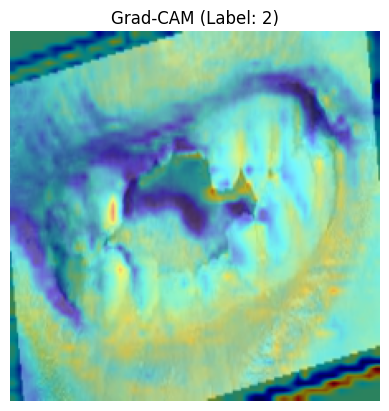

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np
target_layer = model.conv3
data_iter = iter(test_loader)
images, labels = next(data_iter)
image = images[0].unsqueeze(0).to(device)
label = labels[0].item()
cam = GradCAM(model=model, target_layers=[target_layer])


targets = [ClassifierOutputTarget(label)]  # You can set a specific class index if needed
grayscale_cam = cam(input_tensor=image, targets=targets)[0]  # [0] because batch size = 1

# Convert tensor to image
rgb_image = image.cpu().squeeze().permute(1, 2, 0).numpy()
rgb_image = (rgb_image - rgb_image.min()) / (rgb_image.max() - rgb_image.min())  # Normalize

# Overlay the heatmap
visualization = show_cam_on_image(rgb_image, grayscale_cam, use_rgb=True)

# Show it
plt.imshow(visualization)
plt.title(f"Grad-CAM (Label: {label})")
plt.axis('off')
plt.show()